In [7]:
import sys
print(sys.executable)

c:\Users\buwsa\AppData\Local\Programs\Python\Python313\python.exe


In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

games = pd.read_csv('data/Games.csv')
team_stats = pd.read_csv('data/TeamStatistics.csv')

print('Games:', games.shape)
print('Team Statistics:', team_stats.shape)

C:\Users\buwsa\AppData\Local\Temp\ipykernel_16368\2310521022.py:5: DtypeWarning: Columns (12: gameSubtype, 14: gameSubLabel, 15: seriesGameNumber, 18: arenaName, 19: arenaCity, 20: arenaState, 21: officials) have mixed types. Specify dtype option on import or set low_memory=False.
  games = pd.read_csv('data/Games.csv')


Games: (73557, 23)
Team Statistics: (147116, 59)


In [9]:
games.head()

,gameId,gameDateTimeEst,hometeamCity,hometeamName,hometeamId,awayteamCity,awayteamName,awayteamId,homeScore,awayScore,...,gameLabel,gameSubLabel,seriesGameNumber,attendance,arenaId,arenaName,arenaCity,arenaState,officials,gameDate
0,22600256,2026-11-17 23:00:00,Los Angeles,Lakers,1610612747,Charlotte,Hornets,1610612766,118,114,...,NaN,NaN,NaN,19057.0,1000069,Crypto.com Arena,Los Angeles,CA,"Zach Zarba, Nick Buchert, Jonathan Sterling",2026-11-17 23:00:00
1,22600257,2026-11-17 22:30:00,LA,Clippers,1610612746,Utah,Jazz,1610612762,107,132,...,NaN,NaN,NaN,14716.0,1000137,Intuit Dome,Inglewood,CA,"James Williams, Andy Nagy, Agon Abazi",2026-11-17 22:30:00
2,22600254,2026-11-17 20:00:00,Minnesota,Timberwolves,1610612750,Portland,Trail Blazers,1610612757,106,105,...,NaN,NaN,NaN,18281.0,61,Target Center,Minneapolis,MN,"Derrick Collins, Brent Barnaky, Josh Tiven",2026-11-17 20:00:00
3,22600255,2026-11-17 20:00:00,San Antonio,Spurs,1610612759,Detroit,Pistons,1610612765,93,105,...,NaN,NaN,NaN,18412.0,1000118,Frost Bank Center,San Antonio,TX,"James Capers, Che Flores, Biniam Maru",2026-11-17 20:00:00
4,22600253,2026-11-17 19:30:00,Toronto,Raptors,1610612761,New York,Knicks,1610612752,102,111,...,NaN,NaN,NaN,19800.0,643,Scotiabank Arena,Toronto,ON,"Eric Lewis, Mitchell Ervin, Evan Scott",2026-11-17 19:30:00


In [10]:
team_stats.head()

,gameId,gameDateTimeEst,teamCity,teamName,teamId,opponentTeamCity,opponentTeamName,opponentTeamId,home,win,...,gameLabel,gameSubLabel,seriesGameNumber,seed,reboundsTeam,turnoversTeam,ot1Points,ot2Points,otAllPoints,gameDate
0,22600256,2026-11-17 23:00:00,Charlotte,Hornets,1610612766,Los Angeles,Lakers,1610612747,0,0.0,...,NaN,NaN,NaN,NaN,5.0,2.0,3.0,NaN,3.0,2026-11-17 23:00:00
1,22600256,2026-11-17 23:00:00,Los Angeles,Lakers,1610612747,Charlotte,Hornets,1610612766,1,1.0,...,NaN,NaN,NaN,NaN,14.0,1.0,7.0,NaN,7.0,2026-11-17 23:00:00
2,22600257,2026-11-17 22:30:00,Utah,Jazz,1610612762,LA,Clippers,1610612746,0,1.0,...,NaN,NaN,NaN,NaN,9.0,1.0,NaN,NaN,NaN,2026-11-17 22:30:00
3,22600257,2026-11-17 22:30:00,LA,Clippers,1610612746,Utah,Jazz,1610612762,1,0.0,...,NaN,NaN,NaN,NaN,8.0,0.0,NaN,NaN,NaN,2026-11-17 22:30:00
4,22600254,2026-11-17 20:00:00,Minnesota,Timberwolves,1610612750,Portland,Trail Blazers,1610612757,1,1.0,...,NaN,NaN,NaN,NaN,14.0,1.0,NaN,NaN,NaN,2026-11-17 20:00:00


In [5]:
print("Games missing values:")
print(games.isna().sum().sort_values(ascending=False))

print("\nTeam Statistics missing values:")
print(team_stats.isna().sum().sort_values(ascending=False))

Games missing values:
gameSubtype         73452
gameSubLabel        73197
arenaState          71890
attendance          71887
officials           71879
arenaCity           71879
arenaName           71879
gameLabel           69418
seriesGameNumber    67734
hometeamCity            7
awayteamCity            7
gameId                  0
arenaId                 0
gameType                0
gameDateTimeEst         0
winner                  0
awayScore               0
homeScore               0
awayteamId              0
awayteamName            0
hometeamId              0
hometeamName            0
gameDate                0
dtype: int64

Team Statistics missing values:
coachId                    147116
ot2Points                  146008
ot1Points                  139268
otAllPoints                139264
seed                       139244
seriesGameNumber           138238
gameSubLabel               137824
gameLabel                  137614
q4Points                     7900
q3Points                    

In [7]:
print("Earliest game:", games['gameDate'].min())
print("Latest game:", games['gameDate'].max())

Earliest game: 1946-11-26 19:00:00
Latest game: 2026-11-17 23:00:00


In [40]:
# Focus on regular-season games
regular_games = games[games['gameType'] == 'Regular Season']

# Select important team performance variables
features = [
    'teamScore',
    'assists',
    'reboundsTotal',
    'turnovers',
    'fieldGoalsPercentage',
    'threePointersPercentage'
]

regular_team_stats = team_stats[
    team_stats['gameId'].isin(regular_games['gameId'])
]

# Calculate seven-number summaries
summary = regular_team_stats[features].describe()

summary.loc[
    ['mean', 'std', 'min', '25%', '50%', '75%', 'max']
]


,teamScore,assists,reboundsTotal,turnovers,fieldGoalsPercentage,threePointersPercentage
mean,104.561041,17.610738,32.493304,10.568157,0.350402,0.243331
std,14.241781,11.215085,19.506162,7.577078,0.205259,0.198450
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,95.000000,10.000000,27.000000,0.000000,0.330000,0.000000
50%,104.000000,21.000000,40.000000,12.000000,0.438000,0.286000
75%,114.000000,26.000000,46.000000,16.000000,0.488000,0.391000
max,186.000000,89.000000,109.000000,40.000000,5.125000,1.000000


In [9]:
print('Game types:')
print(games['gameType'].value_counts(dropna=False))

print('\nHome vs away:')
print(regular_team_stats['home'].value_counts(dropna=False))

print('\nWins vs losses:')
print(regular_team_stats['win'].value_counts(dropna=False))


Game types:
gameType
Regular Season        66979
Playoffs               4526
Preseason              1940
NBA Emirates Cup         66
Play-in Tournament       37
All-Star Game             7
Emirates NBA Cup          1
NBA Cup                   1
Name: count, dtype: int64

Home vs away:
home
1    66981
0    66979
Name: count, dtype: int64

Wins vs losses:
win
0.0    66979
1.0    66979
NaN        2
Name: count, dtype: int64


## Teams' Visualilzation

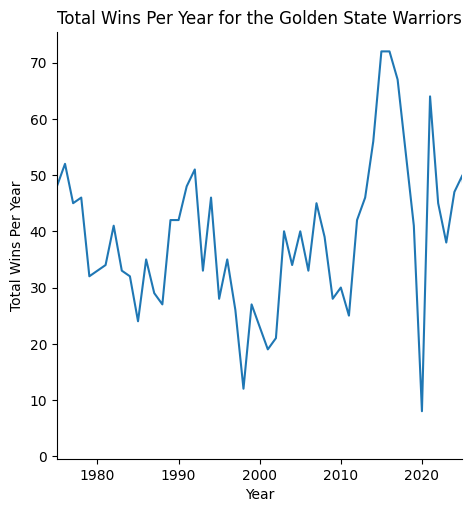

In [71]:
warriors_stats = regular_team_stats[regular_team_stats['teamName'] == 'Warriors'].copy()
warriors_stats['year'] = pd.to_datetime(warriors_stats['gameDateTimeEst']).dt.year

warriors_wins_by_year = (
    warriors_stats.groupby('year')['win'].sum()
    .reset_index(name='total_wins')
)

w = sns.relplot(x='year', y='total_wins', data=warriors_wins_by_year, kind='line')
plt.xlim(1975, 2025)
plt.xlabel('Year')
plt.ylabel('Total Wins Per Year')
plt.title('Total Wins Per Year for the Golden State Warriors')
plt.savefig('warriors_win.png', bbox_inches='tight')


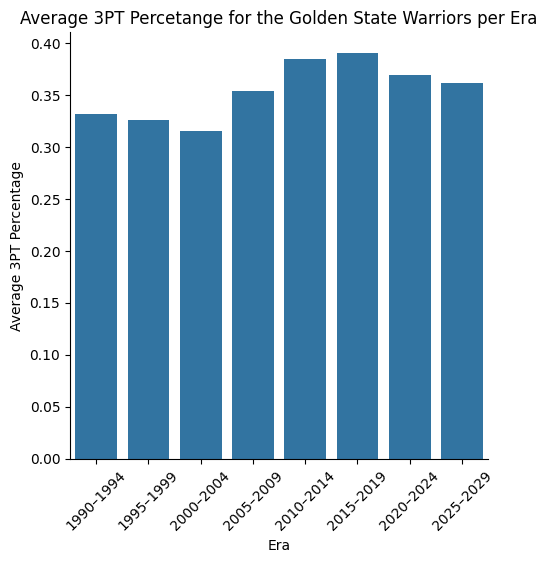

In [70]:
def by_era(year:int):
    start_year = year - year % 5
    end_year = year + (5 - year % 5)
    return (start_year, end_year)

recent = warriors_stats[warriors_stats['year'] >= 1990].copy()
recent['era'] = recent['year'].apply(by_era)
warriors_three_point_by_era = (
    recent.groupby('era')['threePointersPercentage'].mean()
    .reset_index(name='three_point')
)
warriors_three_point_by_era['era_label'] = warriors_three_point_by_era['era'].apply(
    lambda era: f'{era[0]}–{era[1] - 1}'
)

g = sns.catplot(x='era_label', y='three_point', data=warriors_three_point_by_era, kind='bar')
g.set_xticklabels(rotation=45)
plt.xlabel('Era')
plt.ylabel('Average 3PT Percentage')
plt.title('Average 3PT Percetange for the Golden State Warriors per Era')
plt.savefig('warriors_3pt.png', bbox_inches='tight')

In [73]:
# by_era
assert by_era(1992) == (1990, 1995)
assert by_era(1988) == (1985, 1990)
assert by_era(2000) == (2000, 2005)

# data loaded
assert len(games) > 0
assert len(team_stats) > 0

# filtering
assert (regular_games['gameType'] == 'Regular Season').all()
assert (warriors_stats['teamName'] == 'Warriors').all()

# wins can't be negative
assert (warriors_wins_by_year['total_wins'] >= 0).all()
